# Exploratory Data Analysis on Used Cars Dataset

Student: Samruddhi P J  
Program: Artificial Intelligence
Batch: September  
Project: Cars EDA  
Dataset: Vehicle Dataset from CarDekho (Kaggle)

### Project objective
Perform a complete Exploratory Data Analysis to understand the used-car dataset, improve data quality, identify patterns and outliers, and communicate useful findings through clear visualisations.


## 1. Dataset source

Primary source: Kaggle – Vehicle Dataset from CarDekho
Kaggle URL: https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho

The dataset contains used-car attributes including car name, year, selling price, kilometres driven, fuel type, seller type, transmission and ownership status.






## 2. Import libraries

In [3]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the dataset

In [4]:
from google.colab import files
import pandas as pd

# Upload the CSV file downloaded from Kaggle
uploaded = files.upload()

# Get the uploaded file name
file_name = list(uploaded.keys())[0]

# Load the dataset
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("File name:", file_name)
print("Dataset shape:", df.shape)

Saving CAR DETAILS FROM CAR DEKHO.csv to CAR DETAILS FROM CAR DEKHO (1).csv
Dataset loaded successfully!
File name: CAR DETAILS FROM CAR DEKHO (1).csv
Dataset shape: (4340, 8)


## 4. Initial inspection

The assignment requires the shape, column names, sample records and data types to be shown before cleaning.

In [5]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
display(df.dtypes)

print("\nDataset information:")
df.info()

Shape: (4340, 8)

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

First 5 rows:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner



Data types:


,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


## 5. Separate numerical and categorical variables

In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['year', 'selling_price', 'km_driven']
Categorical columns: ['name', 'fuel', 'seller_type', 'transmission', 'owner']


## 6. Data-quality checks

We check:
- missing values
- exact duplicate rows
- unique category labels
- impossible or unsuitable numeric values

In [7]:
missing_values = df.isnull().sum().sort_values(ascending=False)
duplicate_count = df.duplicated().sum()

print("Missing values:")
display(missing_values.to_frame("missing_count"))

print("Exact duplicate rows:", duplicate_count)

for col in ["fuel", "seller_type", "transmission", "owner"]:
    print(f"\nUnique values in {col}:")
    print(sorted(df[col].dropna().unique().tolist()))

Missing values:


,missing_count
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


Exact duplicate rows: 763

Unique values in fuel:
['CNG', 'Diesel', 'Electric', 'LPG', 'Petrol']

Unique values in seller_type:
['Dealer', 'Individual', 'Trustmark Dealer']

Unique values in transmission:
['Automatic', 'Manual']

Unique values in owner:
['First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner']


## 7. Cleaning decisions

### Decisions used
1. Standardise column names to lowercase with underscores.
2. Remove leading/trailing spaces from text fields.
3. Standardise text labels to title case where appropriate.
4. Convert `year`, `selling_price` and `km_driven` to numeric.
5. Remove exact duplicate rows because they repeat the same complete listing record.
6. Do **not** automatically remove high-price or high-mileage records. They are treated as potential outliers and investigated instead, because luxury cars and heavily driven vehicles can be genuine records.
7. Missing values are reported; if present, they are handled only where justified.

In [8]:
# Standardise column names
df_clean = df.copy()
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Clean text fields
text_cols = df_clean.select_dtypes(include="object").columns
for col in text_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# Standardise known categorical labels
for col in ["fuel", "seller_type", "transmission", "owner"]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].str.replace(r"\s+", " ", regex=True).str.strip()

# Convert numeric columns safely
for col in ["year", "selling_price", "km_driven"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

before_rows = len(df_clean)

# Remove exact duplicate rows
duplicate_rows_removed = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

after_rows = len(df_clean)

print(f"Rows before cleaning: {before_rows}")
print(f"Exact duplicate rows removed: {duplicate_rows_removed}")
print(f"Rows after cleaning: {after_rows}")
print(f"Columns after cleaning: {df_clean.shape[1]}")


Rows before cleaning: 4340
Exact duplicate rows removed: 763
Rows after cleaning: 3577
Columns after cleaning: 8


## 8. Check the cleaned dataset

In [9]:
print("Missing values after cleaning:")
display(df_clean.isnull().sum().to_frame("missing_count"))

print("\nData types after cleaning:")
display(df_clean.dtypes)

print("\nCleaned sample:")
display(df_clean.head())

Missing values after cleaning:


,missing_count
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0



Data types after cleaning:


,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object



Cleaned sample:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 9. Create useful derived variables

The assignment asks us to explore vehicle age and brand-related patterns. Brand is extracted from the first word of the car name, and vehicle age is calculated relative to the latest model year present in the dataset

In [10]:
df_clean["brand"] = df_clean["name"].str.split().str[0]

reference_year = int(df_clean["year"].max())
df_clean["vehicle_age"] = reference_year - df_clean["year"]

print("Reference year:", reference_year)
display(df_clean[["name", "brand", "year", "vehicle_age"]].head())

Reference year: 2020


,name,brand,year,vehicle_age
0,Maruti 800 AC,Maruti,2007,13
1,Maruti Wagon R LXI Minor,Maruti,2007,13
2,Hyundai Verna 1.6 SX,Hyundai,2012,8
3,Datsun RediGO T Option,Datsun,2017,3
4,Honda Amaze VX i-DTEC,Honda,2014,6


## 10. Descriptive statistics – numerical variables

In [11]:
print("Numerical descriptive statistics:")
display(df_clean[["year", "selling_price", "km_driven", "vehicle_age"]].describe().T)

print("\nMedian values:")
display(df_clean[["selling_price", "km_driven", "vehicle_age"]].median().to_frame("median"))

Numerical descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
year,"3,577.00","2,012.96",4.25,"1,992.00","2,010.00","2,013.00","2,016.00","2,020.00"
selling_price,"3,577.00","473,912.54","509,301.81","20,000.00","200,000.00","350,000.00","600,000.00","8,900,000.00"
km_driven,"3,577.00","69,250.55","47,579.94",1.00,"36,000.00","60,000.00","90,000.00","806,599.00"
vehicle_age,"3,577.00",7.04,4.25,0.00,4.00,7.00,10.00,28.00



Median values:


,median
selling_price,"350,000.00"
km_driven,"60,000.00"
vehicle_age,7.00


## 11. Descriptive statistics – categorical variables

In [12]:
for col in ["brand", "fuel", "seller_type", "transmission", "owner"]:
    print(f"\n{col} - frequency table")
    display(df_clean[col].value_counts().head(15).to_frame("count"))


brand - frequency table


,count
brand,
Maruti,1072
Hyundai,637
Mahindra,328
Tata,308
Ford,220
Honda,216
Toyota,170
Chevrolet,151
Renault,110



fuel - frequency table


,count
fuel,
Diesel,1800
Petrol,1717
CNG,37
LPG,22
Electric,1



seller_type - frequency table


,count
seller_type,
Individual,2832
Dealer,712
Trustmark Dealer,33



transmission - frequency table


,count
transmission,
Manual,3265
Automatic,312



owner - frequency table


,count
owner,
First Owner,2218
Second Owner,978
Third Owner,289
Fourth & Above Owner,75
Test Drive Car,17


# 12. Univariate analysis

## Chart 1 – Distribution of selling price
Observation: The selling-price distribution is strongly right-skewed, with most observations concentrated at lower prices and a smaller number of expensive cars extending the upper tail.

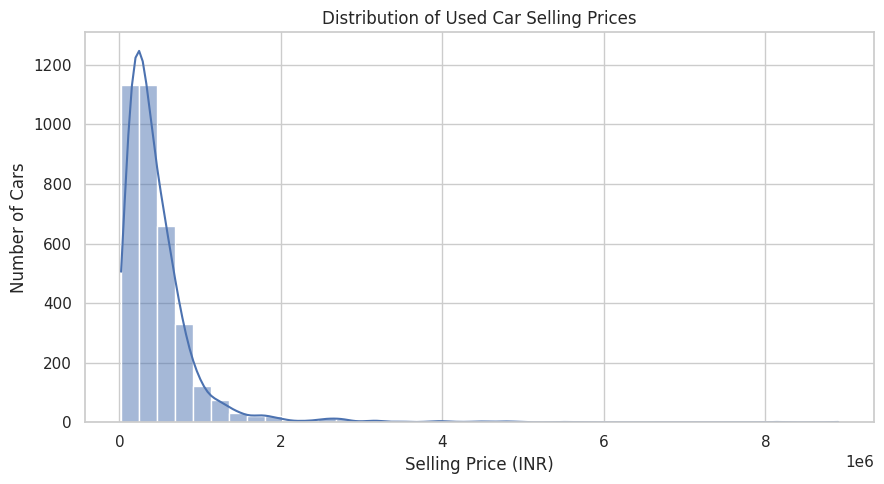

In [13]:
plt.figure(figsize=(9,5))
sns.histplot(df_clean["selling_price"], bins=40, kde=True)
plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (INR)")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

## Chart 2 – Fuel-type distribution
Observation: Petrol and diesel dominate the dataset, while CNG, LPG and electric records form a much smaller share.

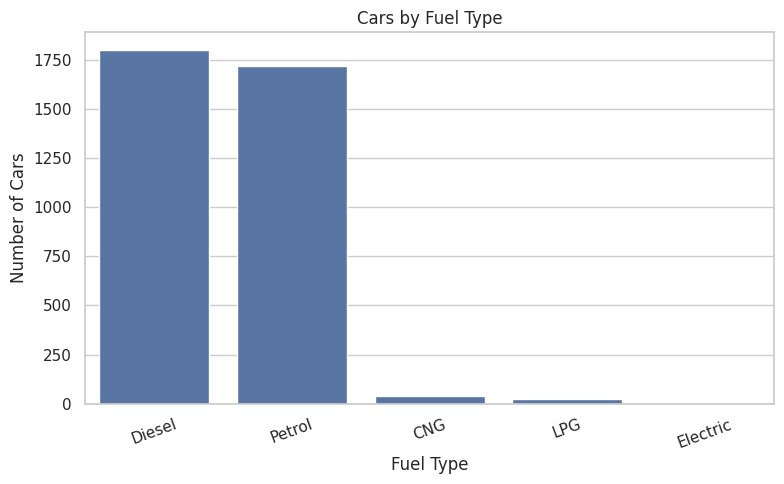

In [14]:
plt.figure(figsize=(8,5))
order = df_clean["fuel"].value_counts().index
sns.countplot(data=df_clean, x="fuel", order=order)
plt.title("Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Chart 3 – Top brands by number of listings
Observation: The dataset is concentrated among a relatively small number of brands, with Maruti and Hyundai contributing many more listings than most other brands.

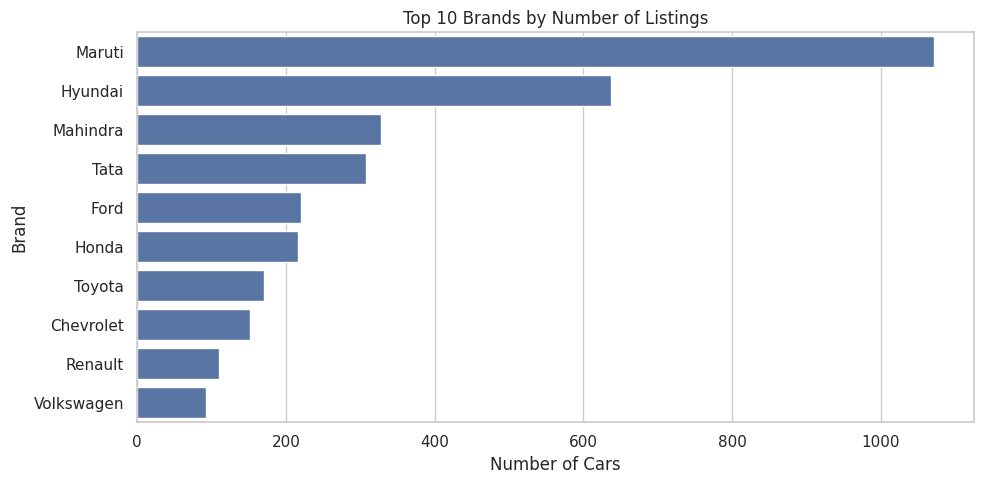

In [15]:
top_brands = df_clean["brand"].value_counts().head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_brands.values, y=top_brands.index)
plt.title("Top 10 Brands by Number of Listings")
plt.xlabel("Number of Cars")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

# 13. Bivariate analysis

## Chart 4 – Vehicle age vs selling price
Observation:Newer vehicles generally occupy higher price ranges, while older vehicles tend to have lower resale prices, although brand and other characteristics create substantial variation.

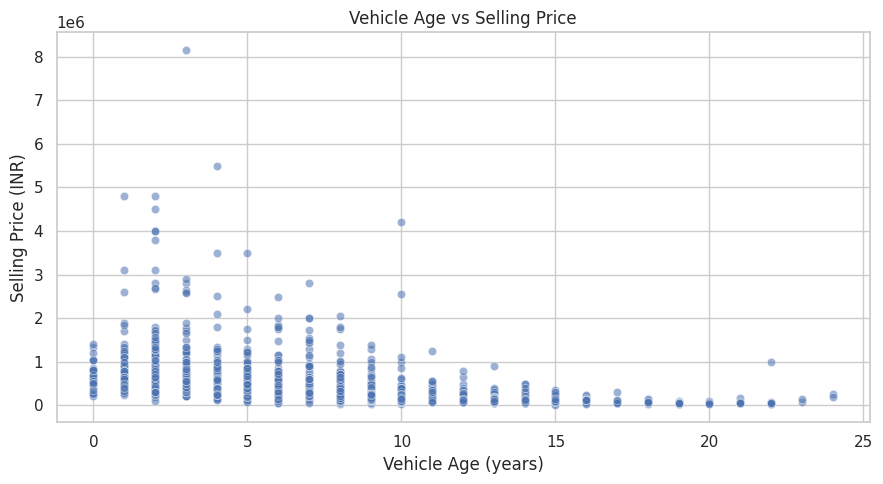

In [16]:
plt.figure(figsize=(9,5))
sns.scatterplot(
    data=df_clean.sample(min(2000, len(df_clean)), random_state=42),
    x="vehicle_age",
    y="selling_price",
    alpha=0.55
)
plt.title("Vehicle Age vs Selling Price")
plt.xlabel("Vehicle Age (years)")
plt.ylabel("Selling Price (INR)")
plt.tight_layout()
plt.show()

## Chart 5 – Kilometres driven vs selling price
Observation:Higher kilometres driven are generally associated with lower resale prices, but the relationship is not perfectly linear and there are important high-value exceptions.

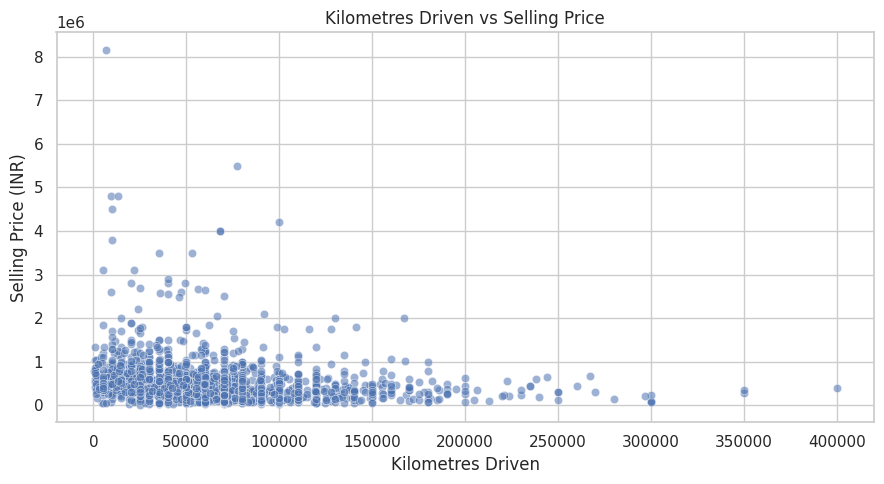

In [17]:
plt.figure(figsize=(9,5))
sns.scatterplot(
    data=df_clean.sample(min(2000, len(df_clean)), random_state=42),
    x="km_driven",
    y="selling_price",
    alpha=0.55
)
plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (INR)")
plt.tight_layout()
plt.show()

## Chart 6 – Transmission and selling price
Observation: Automatic cars occupy a different price distribution from manual cars. Because transmission type is unevenly represented, the comparison should be interpreted as a dataset pattern rather than a universal market rule.

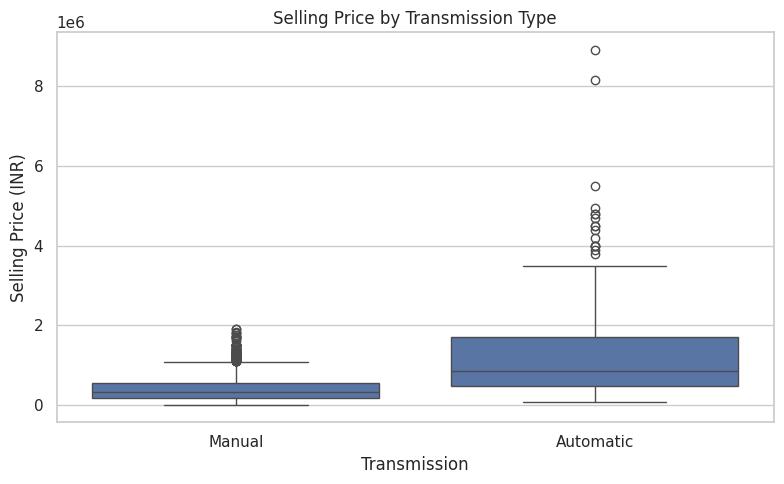

In [18]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df_clean, x="transmission", y="selling_price")
plt.title("Selling Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Selling Price (INR)")
plt.tight_layout()
plt.show()

# 14. Multivariate analysis

## Chart 7 – Correlation heatmap
Observation: Year, vehicle age, kilometres driven and selling price show useful numerical relationships. Vehicle age is the inverse transformation of year, so those two variables are expected to be strongly negatively correlated.

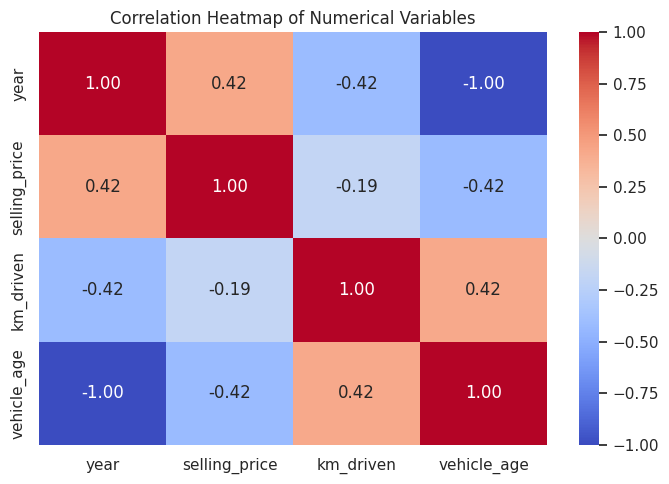

In [19]:
corr_cols = ["year", "selling_price", "km_driven", "vehicle_age"]
corr = df_clean[corr_cols].corr()

plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

## Chart 8 – Average selling price by fuel type
Observation: Average prices differ between fuel categories, but categories with very few observations should not be treated as representative of the broader used-car market.

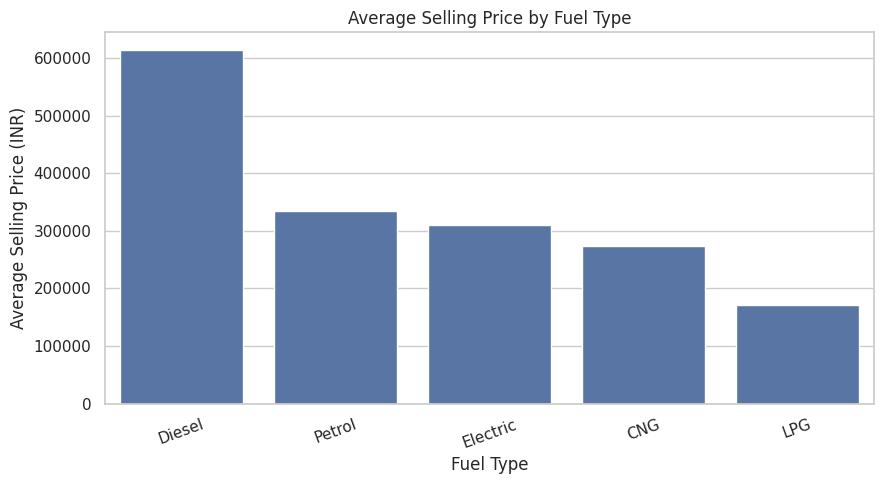

,mean,count
fuel,,
Diesel,"614,001.07",1800
Petrol,"335,344.34",1717
Electric,"310,000.00",1
CNG,"273,162.08",37
LPG,"171,818.14",22


In [20]:
fuel_price = (
    df_clean.groupby("fuel")["selling_price"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

plt.figure(figsize=(9,5))
sns.barplot(
    data=fuel_price.reset_index(),
    x="fuel",
    y="mean"
)
plt.title("Average Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Selling Price (INR)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

display(fuel_price)

# 15. Outlier analysis

The box plots and quantiles are used to identify unusual observations.

A useful approach is to flag values above the 99th percentile for investigation.

In [21]:
for col in ["selling_price", "km_driven"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    iqr_outliers = df_clean[(df_clean[col] < lower) | (df_clean[col] > upper)]

    print(f"\n{col}")
    print("Q1:", q1)
    print("Q3:", q3)
    print("IQR:", iqr)
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("IQR-based outlier count:", len(iqr_outliers))

    p99 = df_clean[col].quantile(0.99)
    print("99th percentile:", p99)


selling_price
Q1: 200000.0
Q3: 600000.0
IQR: 400000.0
Lower bound: -400000.0
Upper bound: 1200000.0
IQR-based outlier count: 170
99th percentile: 2675000.0

km_driven
Q1: 36000.0
Q3: 90000.0
IQR: 54000.0
Lower bound: -45000.0
Upper bound: 171000.0
IQR-based outlier count: 106
99th percentile: 223158.39999999985


# 16. Question-based analysis



In [22]:
print("Most common fuel type:")
print(df_clean["fuel"].value_counts().idxmax())

print("\nMost common seller type:")
print(df_clean["seller_type"].value_counts().idxmax())

print("\nMost common transmission:")
print(df_clean["transmission"].value_counts().idxmax())

print("\nMost common owner category:")
print(df_clean["owner"].value_counts().idxmax())

print("\nTop 10 brands:")
display(df_clean["brand"].value_counts().head(10).to_frame("count"))

print("\nAverage selling price by transmission:")
display(
    df_clean.groupby("transmission")["selling_price"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)


Most common fuel type:
Diesel

Most common seller type:
Individual

Most common transmission:
Manual

Most common owner category:
First Owner

Top 10 brands:


,count
brand,
Maruti,1072
Hyundai,637
Mahindra,328
Tata,308
Ford,220
Honda,216
Toyota,170
Chevrolet,151
Renault,110



Average selling price by transmission:


,mean,median,count
transmission,,,
Automatic,"1,274,955.11","855,000.00",312
Manual,"397,365.75","325,000.00",3265


# 17. Final findings

1. The dataset contains 4,340 used-car records and eight original columns.
2. The data has no missing values in the original published inspection.
3. Exact duplicate rows are present and should be removed before analysis; the commonly reported duplicate check identifies 763 duplicates, leaving 3,577 unique rows.
4. Petrol and diesel make up almost the entire dataset, while alternative-fuel categories have very small counts.
5. Maruti and Hyundai are the two largest brands by listing count in this dataset.
6. Selling price is strongly right-skewed because a small number of expensive vehicles extend the upper tail.
7. Vehicle age and kilometres driven are useful variables for examining resale-price differences, but neither alone explains all price variation.
8. Automatic and manual cars have different price distributions, but the categories are highly imbalanced, so this should be interpreted only as a pattern in this dataset.
9. Extreme prices and kilometre values should be investigated rather than deleted automatically because they may represent genuine luxury or heavily used vehicles.

# 18. Limitations

- The dataset is a snapshot of used-car listings and should not be treated as a complete representation of the entire Indian used-car market.
- The dataset does not include several potentially important pricing variables such as engine size, horsepower, exact vehicle condition, accident history, or location.
- The transmission and alternative-fuel categories are imbalanced.
- Duplicate removal can reduce repeated listings, but it does not prove that every remaining row is an independent real-world transaction.
- EDA identifies associations and patterns; it does not establish causation.

# 19. Conclusion

This EDA cleaned and explored a used-car dataset using structured data-quality checks, descriptive statistics, univariate analysis, bivariate analysis, multivariate analysis and outlier investigation. The analysis highlights the importance of vehicle age, kilometres driven, brand, fuel type and transmission when examining resale-price patterns.

The project follows the assignment requirement to focus on exploratory analysis rather than machine-learning prediction.

## References

1. Kaggle – Vehicle Dataset from CarDekho: https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho
2. Assignment brief supplied by the mentor: *Exploratory Data Analysis on a Cars Dataset*.
3. Public raw mirror used only as an execution fallback: https://raw.githubusercontent.com/bagassenop/cardekho/main/CAR%20DETAILS%20FROM%20CAR%20DEKHO.csv